# Experiment 3: Representation and Whole-Body Support
Four fixed checkpoints only: PILOT V02 (Oct29), PILOT Original (Oct21), UniFP Original, and Pos. Uses each method's own recorded trajectories. No FiLM oscillation analysis or new rollouts.

In [1]:
import os, json, sys, importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebooks/pilot_v02_comparison.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
import pilot_v02_comparison as cohort
cohort = importlib.reload(cohort)
CONFIG = cohort.defaults(ROOT)
# Edit roots/output or individual method run_name/checkpoint_sha256 selectors here.
# Both PILOT entries intentionally have native task b1z1_pact, but distinct IDs.
CONFIG["methods"]


{'unifp': {'task': 'b1z1_unifp_original',
  'display_name': 'UniFP',
  'run_name': 'Oct23_15-25-20_upstream_architecture'},
 'pos': {'task': 'b1z1_ppo_pos',
  'display_name': 'Pos',
  'run_name': 'Oct23_16-58-40_position_only'},
 'pilot_original': {'task': 'b1z1_pact',
  'display_name': 'PILOT (Original)',
  'run_name': 'Oct21_00-46-21_b1z1_pact_improved',
  'film_v02': False},
 'pilot_v02': {'task': 'b1z1_pact',
  'display_name': 'PILOT V02',
  'run_name': 'Oct29_15-14-37_b1z1_pact_improved',
  'film_v02': True}}

In [2]:
CONFIG.update({
    "run_representation": True,
    "run_support": True,  # Independently runnable; set run_representation=False for support only.
    "device": "cuda:0",
    "dynamics": True,  # Offline BARD only when needed; no simulator or training runner.
    "fallback_predictions": True,  # Load frozen checkpoints only to fill missing outputs.
    "balanced_resampling": False,  # All eligible native transitions by default.
    "sampling_budget": None,  # Optional deterministic per-method subset when balancing is enabled.
    "dynamics_batch_size": 1024, "inference_batch_size": 1024,
    "num_workers": 4, "metric_workers": 2, "cpu_blas_threads": 1,
    "cache_enabled": True, "cache_completed_runs": True,
    "rmse_bootstrap_resamples": 10000, "rmse_confidence_level": 0.95,
    "rmse_resampling_seed": 0,
    "contact_window_seconds": 0.1,
    "representation_assume_foot_only_contacts": True,
    "support_legacy_figures": True,  # Retain existing channel/support diagnostic figures.
})
# Optional JSON file for unattended execution; does not modify old notebooks.
if os.environ.get("PILOT_COMPARISON_CONFIG"):
    CONFIG.update(json.loads(Path(os.environ["PILOT_COMPARISON_CONFIG"]).read_text()))



## Representation Quality
Stored predictions first; frozen inference fills missing fields only. Preserve force timing, frames, normal-only sensor labels, momentum-derived net GRFs, explicit velocity/EE estimates, and decoded/measured/constant-velocity rollout variants. Missing heads remain unavailable (UniFP has no complete decoded GRF/moment rollout). BARD requires the existing CUDA/model dependencies; stored force metrics and support analysis do not. Exp1 momentum foot attribution uses the explicit no-other-contact assumption when sensor evidence is absent.

In [3]:
if CONFIG["run_representation"]:
    import exp3_representation as representation
    representation = importlib.reload(representation)
    REP, inventory = cohort.representation_config(CONFIG)
    display(pd.DataFrame(inventory))
    result = representation.run_analysis(REP)
    for path in sorted(Path(result["output_dir"]).glob("native_*_table.csv")):
        display(pd.read_csv(path, header=[0, 1], index_col=0))
    display(pd.DataFrame(result["unavailable"]))
    display(pd.DataFrame([r for r in result["table_summary"] if r["variant"] != "decoded"]))
    print("\n".join(result["diagnostics"]))


,method,task,checkpoint_sha256,recordings,evaluation_seeds,training_seeds,status
0,unifp,b1z1_unifp_original,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,9,"[0, 1, 2]",[],available
1,pos,b1z1_ppo_pos,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,9,"[0, 1, 2]",[],available
2,pilot_original,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,9,"[0, 1, 2]",[],available
3,pilot_v02,b1z1_pact,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,9,"[0, 1, 2]",[],available


Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp1/b1z1_ppo_pos/combine_in/seed_0
  reused 74,315 transitions and per-trial statistics
Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp1/b1z1_ppo_pos/combine_in/seed_1
  reused 73,947 transitions and per-trial statistics
Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp1/b1z1_ppo_pos/combine_in/seed_2
  reused 73,999 transitions and per-trial statistics
Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp1/b1z1_ppo_pos/ee_only_in/seed_0
  reused 74,315 transitions and per-trial statistics
Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp1/b1z1_ppo_pos/ee_only_in/seed_1
  reused 74,900 transitions and per-trial statistics
Exp3: pos: /home/oyoungquist/Research/Genesis_Development/HCR_Gen

nominal                                  \
                   ee force [N] base force [N] base moment [Nm]   
Method                                                            
UniFP             0.435 ± 0.001  1.653 ± 0.031                —   
Pos               5.103 ± 0.025  1.017 ± 0.011    0.097 ± 0.001   
PILOT (Original)  4.204 ± 0.008  1.330 ± 0.019    0.724 ± 0.006   
PILOT V02         2.214 ± 0.010  1.699 ± 0.009    0.479 ± 0.001   

                                                                     \
                 per-foot normal GRF [N] Momentum Net GRF (xyz) [N]   
Method                                                                
UniFP                                  —                          —   
Pos                       29.111 ± 0.030             50.979 ± 0.057   
PILOT (Original)          20.917 ± 0.110             33.762 ± 0.202   
PILOT V02                 21.538 ± 0.059             33.185 ± 0.169   

                                                                          \
                 Momentum Net GRF (xy) [N] Momentum Net GRF (window) [N]   
Method                                                                     
UniFP                                    —                             —   
Pos                         28.587 ± 0.095                43.221 ± 0.056   
PILOT (Original)            28.264 ± 0.099                22.333 ± 0.083   
PILOT V02                   26.922 ± 0.146                18.389 ± 0.103   

                                                              \
                 Error Against Normal-Only Sensor Forces [N]   
Method                                                         
UniFP                                                      —   
Pos                                           17.886 ± 0.025   
PILOT (Original)                              19.608 ± 0.042   
PILOT V02                                     19.157 ± 0.072   

                                                         ...  \
                 base linear [m/s] base angular [rad/s]  ...   
Method                                                   ...   
UniFP                            —                    —  ...   
Pos                  0.016 ± 0.000        0.126 ± 0.003  ...   
PILOT (Original)     0.013 ± 0.000        0.096 ± 0.002  ...   
PILOT V02            0.009 ± 0.000        0.084 ± 0.002  ...   

                               disturbed                             \
                 per-foot normal GRF [N] Momentum Net GRF (xyz) [N]   
Method                                                                
UniFP                                  —                          —   
Pos                       29.464 ± 0.048             55.640 ± 0.462   
PILOT (Original)          23.115 ± 0.135             46.133 ± 0.127   
PILOT V02                 22.576 ± 0.094             43.342 ± 0.112   

                                                                          \
                 Momentum Net GRF (xy) [N] Momentum Net GRF (window) [N]   
Method                                                                     
UniFP                                    —                             —   
Pos                         40.266 ± 0.313                47.528 ± 0.483   
PILOT (Original)            41.857 ± 0.494                36.337 ± 0.138   
PILOT V02                   39.284 ± 0.174                32.694 ± 0.150   

                                                              \
                 Error Against Normal-Only Sensor Forces [N]   
Method                                                         
UniFP                                                      —   
Pos                                           18.168 ± 0.037   
PILOT (Original)                              23.053 ± 0.099   
PILOT V02                                     22.116 ± 0.042   

                                                         \
                 base linear [m/s] base angular [rad/s]   
Method                     

,method,run,component,reason,count,first_transition
0,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,59532,7665e4b9d64b37f4fba2dadb60d37147c5acc2197b06bc...
1,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,59238,04892dbf25f1fdcf7852d225b2f5cfec8bb5e0161f871e...
2,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,59280,9c4656b15372e83e37888284245a66201f18092c4125c5...
3,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,59532,bf6963cfbe0569970131ae700ae0968141b129d519288e...
4,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,60000,92cf73de0720a461eab28874fddec80dabc0a52ee373d2...
5,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,59531,52016ff4b2923016862c0396a244ae0a293b26b90da71f...
6,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,60000,1d91e2e515359d6fb4934fadf64c944a991a225b6e2bd1...
7,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,60000,6685a984d24d9c7ee197079f4730a31737a3da0b712abc...
8,pos,/home/oyoungquist/Research/Genesis_Development...,grf_net_window,Nonfinite/empty error; excluded from this metric,60000,9ec6f371579e62f75ed5c5290c122ead2947210e328165...
9,unifp,/home/oyoungquist/Research/Genesis_Development...,base_moment,Decoder output unavailable; no measured substi...,71752,de00740dc0a3e3c4ac557b71f1fcdbab79d05890a91eef...


,method,benchmark,variant,load_range,condition,motion,phase,load_timing,metric,axis,mean,sd,contributing_seeds,bias,contributing_trials,contributing_samples
0,pilot_original,native,constant_velocity,in,disturbed,all,all,all,arm_velocity_rmse,all,0.530139,0.003908,3,0.001304,600,448698
1,pilot_original,native,constant_velocity,in,disturbed,all,all,all,arm_velocity_rmse,z1_elbow,0.408039,0.004253,3,-0.003902,600,448698
2,pilot_original,native,constant_velocity,in,disturbed,all,all,all,arm_velocity_rmse,z1_forearm_roll,0.841366,0.003533,3,-0.000294,600,448698
3,pilot_original,native,constant_velocity,in,disturbed,all,all,all,arm_velocity_rmse,z1_jointGripper,0.009982,0.000078,3,-0.000042,600,448698
4,pilot_original,native,constant_velocity,in,disturbed,all,all,all,arm_velocity_rmse,z1_shoulder,0.329310,0.002241,3,0.002313,600,448698
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
779,unifp,native,measured_loading,in,nominal,all,all,all,leg_velocity_rmse,RL_thigh_joint,0.630750,0.008927,3,0.451440,300,224700
780,unifp,native,measured_loading,in,nominal,all,all,all,leg_velocity_rmse,RR_calf_joint,1.207391,0.000695,3,0.052994,300,224700
781,unifp,native,measured_loading,in,nominal,all,all,all,leg_velocity_rmse,RR_hip_joint,0.645769,0.001236,3,-0.036057,300,224700
782,unifp,native,measured_loading,in,nominal,all,all,all,leg_velocity_rmse,RR_thigh_joint,0.394333,0.003166,3,-0.107878,300,224700


## V02 Versus Each Comparator: Paired Trial RMSE
The existing trial bootstrap now contrasts V02 with Original PILOT, UniFP, and Pos. Pairing verifies recorded scenarios and initial conditions, not seed numbers alone. Export both own pre-failure and exact common pre-failure time windows. Negative differences favor V02 for errors. These are checkpoint comparisons, **not isolated representation-PINN ablations**. Physical states can differ even at common times; absent decoded outputs do not become measured-loading results.

In [4]:
if CONFIG["run_representation"]:
    representation_ci = cohort.representation_confidence_intervals(result, CONFIG)
    display(pd.DataFrame(result["paired_rollout"]["summary"]))
    print("\n".join(result["paired_rollout"]["diagnostics"]))
    display(representation_ci)
    print("Dedicated trial CIs:", Path(result["output_dir"]) / "representation_rollout_confidence_intervals.csv")
    print("All-metric seed CIs:", Path(result["output_dir"]) / "representation_metric_confidence_intervals.csv")


,pair_id,pair,enabled_method,baseline_method,enabled_checkpoint,baseline_checkpoint,condition,load_range,motion,scope,...,baseline_mean,difference,reduction_percent,ci_low,ci_high,reduction_ci_low,reduction_ci_high,p_value,ci_excludes_zero,p_holm
0,"[""pilot_v02"",""pilot_original""]",PILOT V02 vs PILOT (Original),pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,combined-disturbance,in,locomotion,common_pre_failure,...,0.796001,-0.212851,26.739984,-0.241736,-0.183956,22.778829,30.524115,None,True,None
1,"[""pilot_v02"",""pilot_original""]",PILOT V02 vs PILOT (Original),pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,combined-disturbance,in,locomotion,common_pre_failure,...,0.218753,-0.022169,10.134364,-0.026525,-0.017745,8.281697,11.937802,None,True,None
2,"[""pilot_v02"",""pilot_original""]",PILOT V02 vs PILOT (Original),pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,combined-disturbance,in,locomotion,common_pre_failure,...,0.021221,-0.003092,14.572653,-0.003491,-0.002683,12.923300,16.123663,None,True,None
3,"[""pilot_v02"",""pilot_original""]",PILOT V02 vs PILOT (Original),pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,combined-disturbance,in,locomotion,common_pre_failure,...,0.043909,-0.003184,7.250705,-0.004074,-0.002255,5.154926,9.207330,None,True,None
4,"[""pilot_v02"",""pilot_original""]",PILOT V02 vs PILOT (Original),pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,combined-disturbance,in,locomotion,common_pre_failure,...,0.022971,0.002357,-10.262959,0.001905,0.002832,-12.372468,-8.233686,None,True,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,"[""pilot_v02"",""unifp""]",PILOT V02 vs UniFP,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,nominal,in,stationary,own_pre_failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,False,None
248,"[""pilot_v02"",""unifp""]",PILOT V02 vs UniFP,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,nominal,in,stationary,own_pre_failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,False,None
249,"[""pilot_v02"",""unifp""]",PILOT V02 vs UniFP,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,nominal,in,stationary,own_pre_failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,False,None
250,"[""pilot_v02"",""unifp""]",PILOT V02 vs UniFP,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,nominal,in,stationary,own_pre_failure,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,False,None


PILOT V02 vs UniFP: checkpoint/method comparison, not an isolated representation-PINN ablation.
PILOT V02 vs Pos: checkpoint/method comparison, not an isolated representation-PINN ablation.
PILOT V02 vs PILOT (Original): checkpoint/method comparison, not an isolated representation-PINN ablation.
900 trial pairs excluded: initial mechanics/state mismatch: joint_position
Missing/nonfinite velocity data or empty shared samples excluded per metric; attempted pairs retained.


,variant,load_range,condition,motion,phase,load_timing,metric,axis,scope,statistic,...,comparator_available_seeds,confidence_level,bootstrap_resamples,resampling_unit,status,reference_mean,comparator_mean,difference,ci_low,ci_high
0,constant_velocity,in,combined-disturbance,locomotion,0,sustained,arm_velocity_rmse,all,breakdown,bias,...,3,0.95,10000,paired evaluation seed,available,0.003396,0.002763,0.000633,0.000454,0.000912
1,constant_velocity,in,combined-disturbance,locomotion,0,sustained,arm_velocity_rmse,all,breakdown,bias,...,3,0.95,10000,paired evaluation seed,available,0.003396,0.000553,0.002843,0.002673,0.002943
2,constant_velocity,in,combined-disturbance,locomotion,0,sustained,arm_velocity_rmse,all,breakdown,bias,...,3,0.95,10000,paired evaluation seed,available,0.003396,0.003145,0.000250,0.000044,0.000396
3,constant_velocity,in,combined-disturbance,locomotion,0,sustained,arm_velocity_rmse,all,breakdown,mean,...,3,0.95,10000,paired evaluation seed,available,0.464089,0.413036,0.051053,0.048659,0.053214
4,constant_velocity,in,combined-disturbance,locomotion,0,sustained,arm_velocity_rmse,all,breakdown,mean,...,3,0.95,10000,paired evaluation seed,available,0.464089,0.337318,0.126771,0.125135,0.128481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23299,measured_loading,in,nominal,stationary,0,sustained,leg_velocity_rmse,all,breakdown,bias,...,3,0.95,10000,paired evaluation seed,available,-0.033066,0.043120,-0.076186,-0.076462,-0.075957
23300,measured_loading,in,nominal,stationary,0,sustained,leg_velocity_rmse,all,breakdown,bias,...,3,0.95,10000,paired evaluation seed,available,-0.033066,0.141613,-0.174678,-0.176126,-0.173694
23301,measured_loading,in,nominal,stationary,0,sustained,leg_velocity_rmse,all,breakdown,mean,...,3,0.95,10000,paired evaluation seed,available,0.820939,0.752025,0.068914,0.060665,0.075395
23302,measured_loading,in,nominal,stationary,0,sustained,leg_velocity_rmse,all,breakdown,mean,...,3,0.95,10000,paired evaluation seed,available,0.820939,0.573767,0.247172,0.244544,0.252058


Dedicated trial CIs: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp3/representation/full_recorded_first/representation_rollout_confidence_intervals.csv
All-metric seed CIs: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp3/representation/full_recorded_first/representation_metric_confidence_intervals.csv


## Action Channels and Support Redistribution
Retain commanded-geometry and actual EE errors, arm/leg PD and feedforward usage, cancellation, normal-support redistribution, momentum support, and survivor counts. Requested motor/branch-scaled channels remain distinct from executed torque. RMS is computed from substep squares; mean-square plots retain squared units. Geometry uses the existing mean-delayed-command FK approximation. Recorded sensor forces are normal-only; momentum-derived support is a dynamics-consistency reference. No force-balance closure is interpreted as better control.

,method,task,checkpoint_sha256,recordings,evaluation_seeds,training_seeds,status
0,unifp,b1z1_unifp_original,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,9,"[0, 1, 2]",[],available
1,pos,b1z1_ppo_pos,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,9,"[0, 1, 2]",[],available
2,pilot_original,b1z1_pact,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,9,"[0, 1, 2]",[],available
3,pilot_v02,b1z1_pact,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,9,"[0, 1, 2]",[],available


Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_1
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_2
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_0
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_1
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pulling/loaded/seed_2
Exp3 support: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/pushing/loaded/seed_0
Exp3 support: /home/oyoungquist

,task,profile,loading,stage,metric,mean,sd,checkpoints,contributing_seeds,evaluation_repetitions,variability_replicates,variability
0,pilot_original,carrying,loaded,0,all_support_fx_n,0.000076,2.481958e-09,1,3,3,3,evaluation_seed_sd
1,pilot_original,carrying,loaded,0,all_support_fy_n,0.000000,0.000000e+00,1,3,3,3,evaluation_seed_sd
2,pilot_original,carrying,loaded,0,all_support_fz_n,568.877696,1.847260e-02,1,3,3,3,evaluation_seed_sd
3,pilot_original,carrying,loaded,0,all_support_mx_nm,0.004808,4.500424e-02,1,3,3,3,evaluation_seed_sd
4,pilot_original,carrying,loaded,0,all_support_my_nm,-0.087349,2.917543e-02,1,3,3,3,evaluation_seed_sd
...,...,...,...,...,...,...,...,...,...,...,...,...
4423,unifp,pushing,loaded,8,momentum_contact_fz_n,567.149426,3.673117e-02,1,3,3,3,evaluation_seed_sd
4424,unifp,pushing,loaded,8,momentum_contact_interaction_n,0.372807,4.150378e-02,1,3,3,3,evaluation_seed_sd
4425,unifp,pushing,loaded,8,momentum_minus_normal_fz_n,-0.000028,9.497701e-07,1,3,3,3,evaluation_seed_sd
4426,unifp,pushing,loaded,8,rear_normal_support_n,233.680702,4.601421e-01,1,3,3,3,evaluation_seed_sd


,profile,loading,stage,metric,unit,reference_method,comparator_method,reference_checkpoint,comparator_checkpoint,evaluation_seeds,...,comparator_available_seeds,confidence_level,bootstrap_resamples,resampling_unit,status,reference_mean,comparator_mean,difference,ci_low,ci_high
0,carrying,loaded,0,all_support_fx_n,N,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.000076,0.000076,7.763027e-10,1.839345e-10,1.503667e-09
1,carrying,loaded,0,all_support_fx_n,N,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.000076,0.000076,1.251474e-09,2.160007e-10,1.886385e-09
2,carrying,loaded,0,all_support_fx_n,N,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,3,...,3,0.95,10000,paired evaluation seed,available,0.000076,0.000076,-3.563205e-09,-4.463206e-09,-2.562469e-09
3,carrying,loaded,0,all_support_fy_n,N,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
4,carrying,loaded,0,all_support_fy_n,N,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3316,pushing,loaded,8,rear_normal_support_n,N,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,234.912766,283.787406,-4.887464e+01,-4.894680e+01,-4.879100e+01
3317,pushing,loaded,8,rear_normal_support_n,N,pilot_v02,pilot_original,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,2eaf0240106b78e6423f2d6e310318d72b1da561c1af35...,3,...,3,0.95,10000,paired evaluation seed,available,234.912766,253.956342,-1.904358e+01,-1.933505e+01,-1.878814e+01
3318,pushing,loaded,8,velocity_error_m_s,m/s,pilot_v02,unifp,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,3950bf33b7112f11a01fbf3f973a87ddf5d34abaf34d0b...,3,...,3,0.95,10000,paired evaluation seed,available,0.027163,0.042097,-1.493432e-02,-1.589281e-02,-1.425855e-02
3319,pushing,loaded,8,velocity_error_m_s,m/s,pilot_v02,pos,e4cb916f35a8fa096c96c72e8ce6577ceaf2f7a78dfde6...,5b08e70fb898608e3a152bb39c9dc03a03baf6eade2175...,3,...,3,0.95,10000,paired evaluation seed,available,0.027163,0.025922,1.240750e-03,1.060117e-03,1.344857e-03


/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0: base_force_world: collector-held actual load over [t,t+dt)
/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0: ee_force_applied_world_interval_mean: recorded interval average
/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0: momentum_contact_fx_n unavailable/nonfinite on 50 valid rows
/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0: momentum_contact_fy_n unavailable/nonfinite on 50 valid rows
/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/evaluation/exp2/b1z1_pact/carrying/loaded/seed_0: momentum_contact_fz_n unavailable/nonfinite on 50 valid rows
/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_

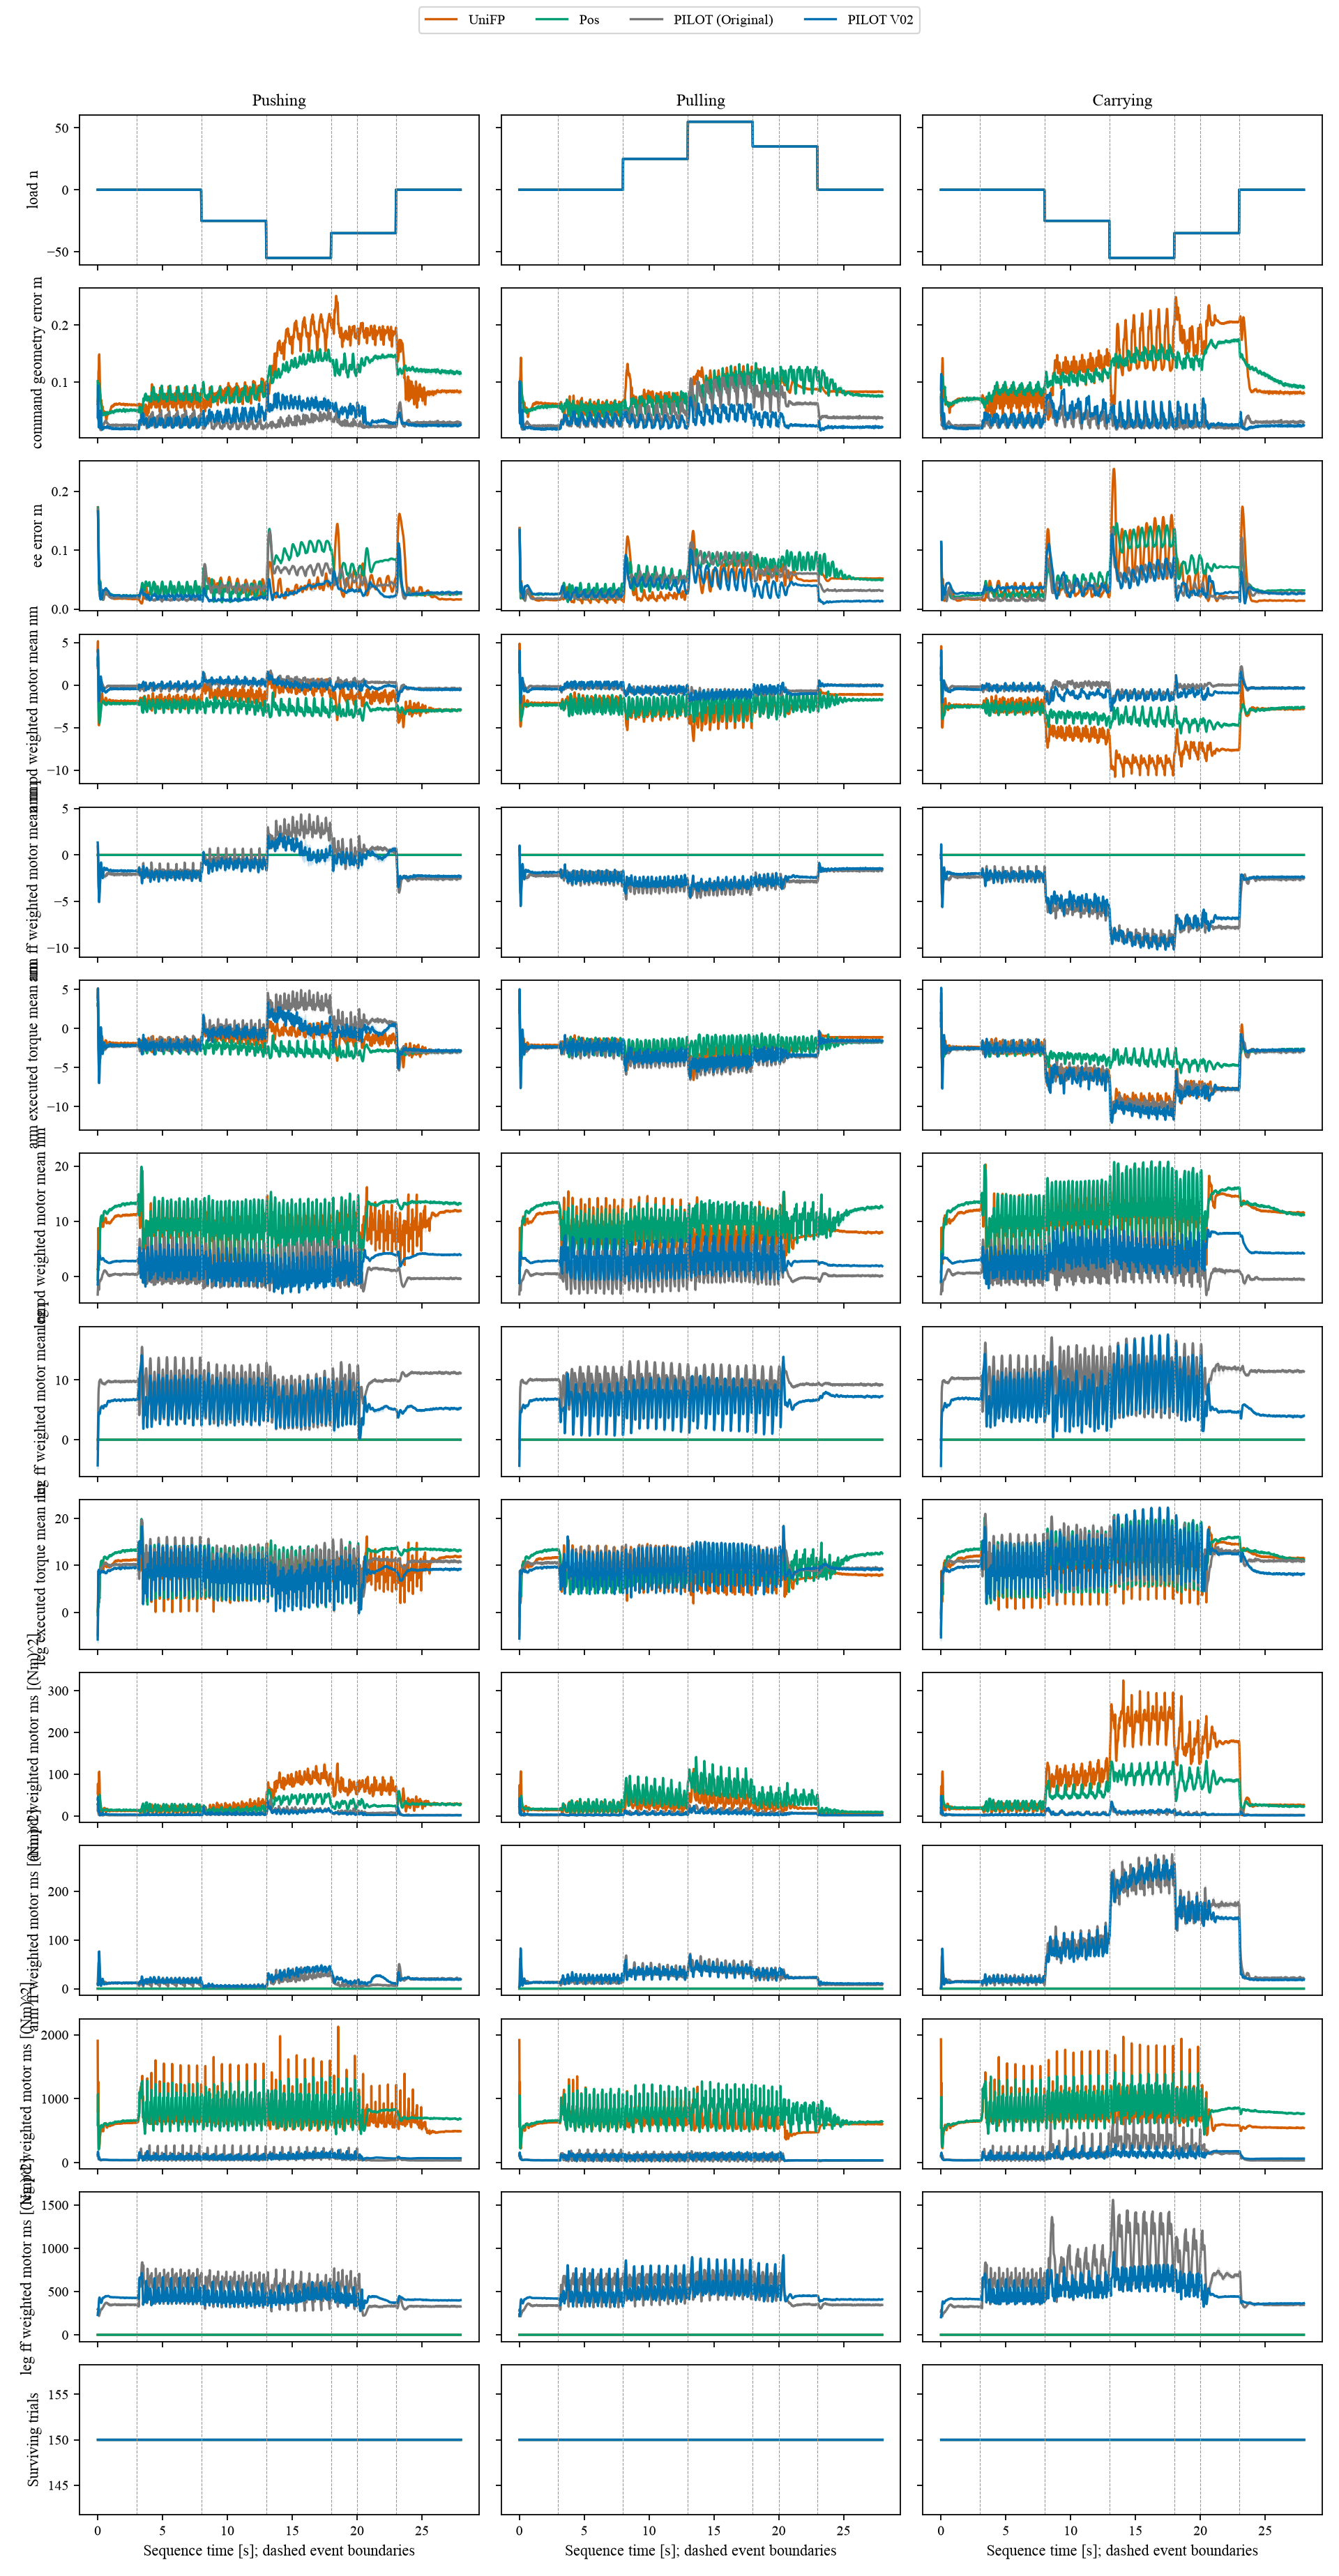

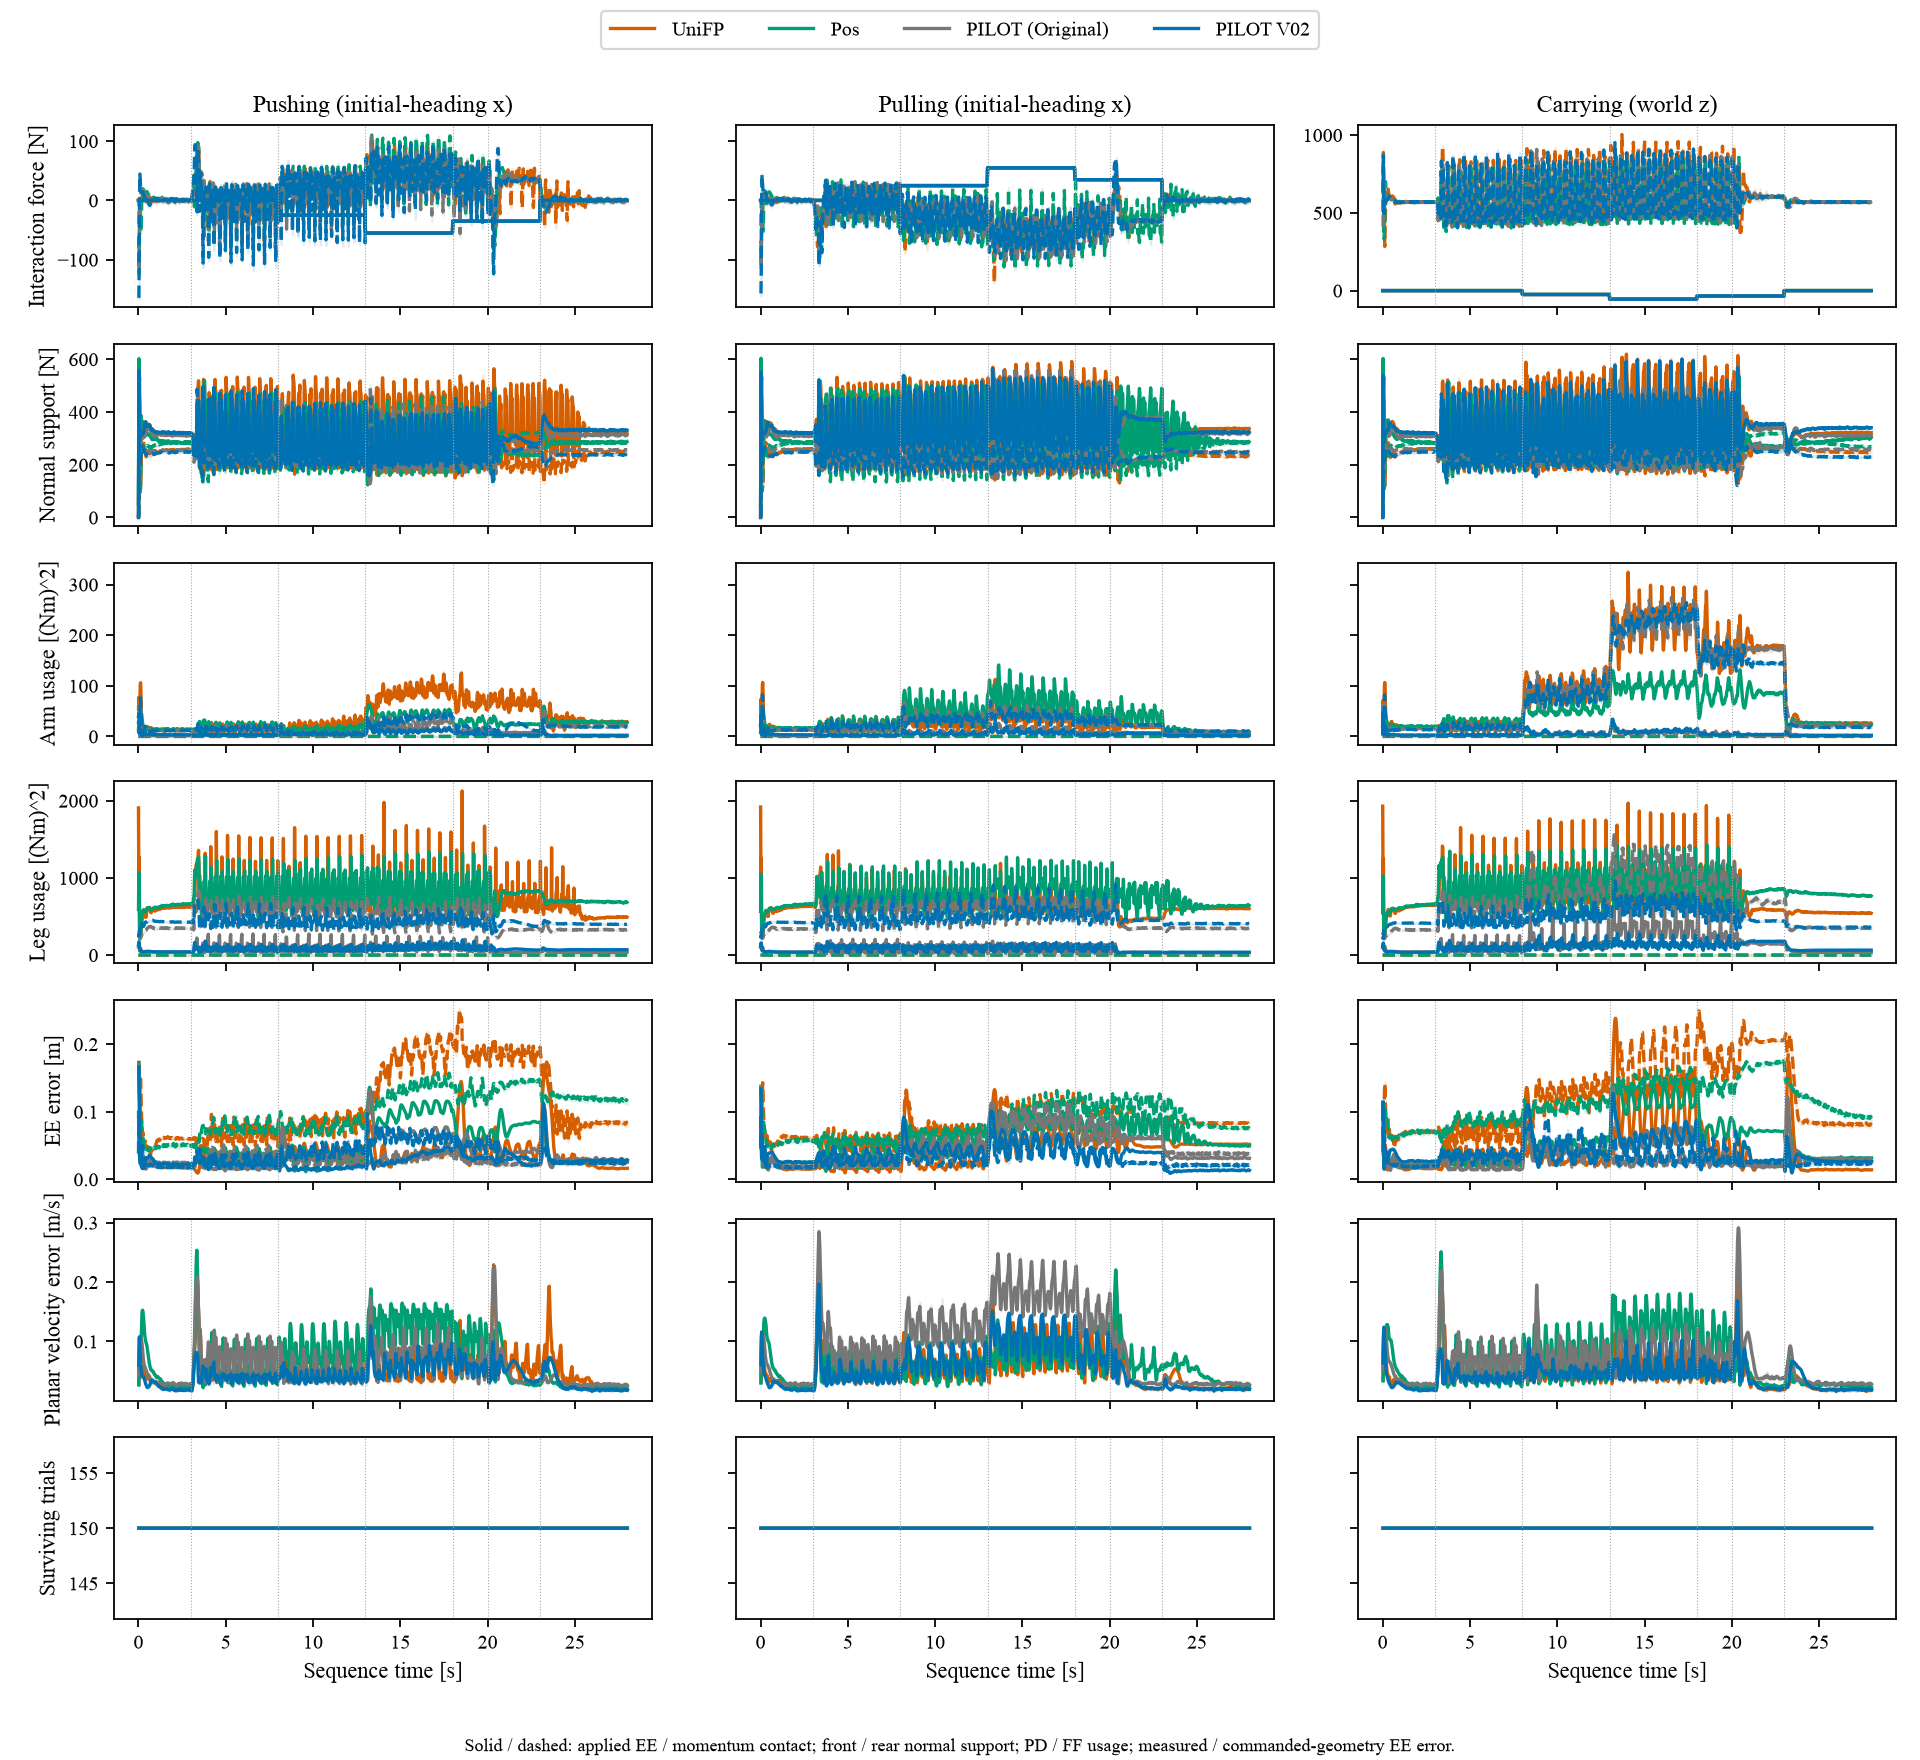

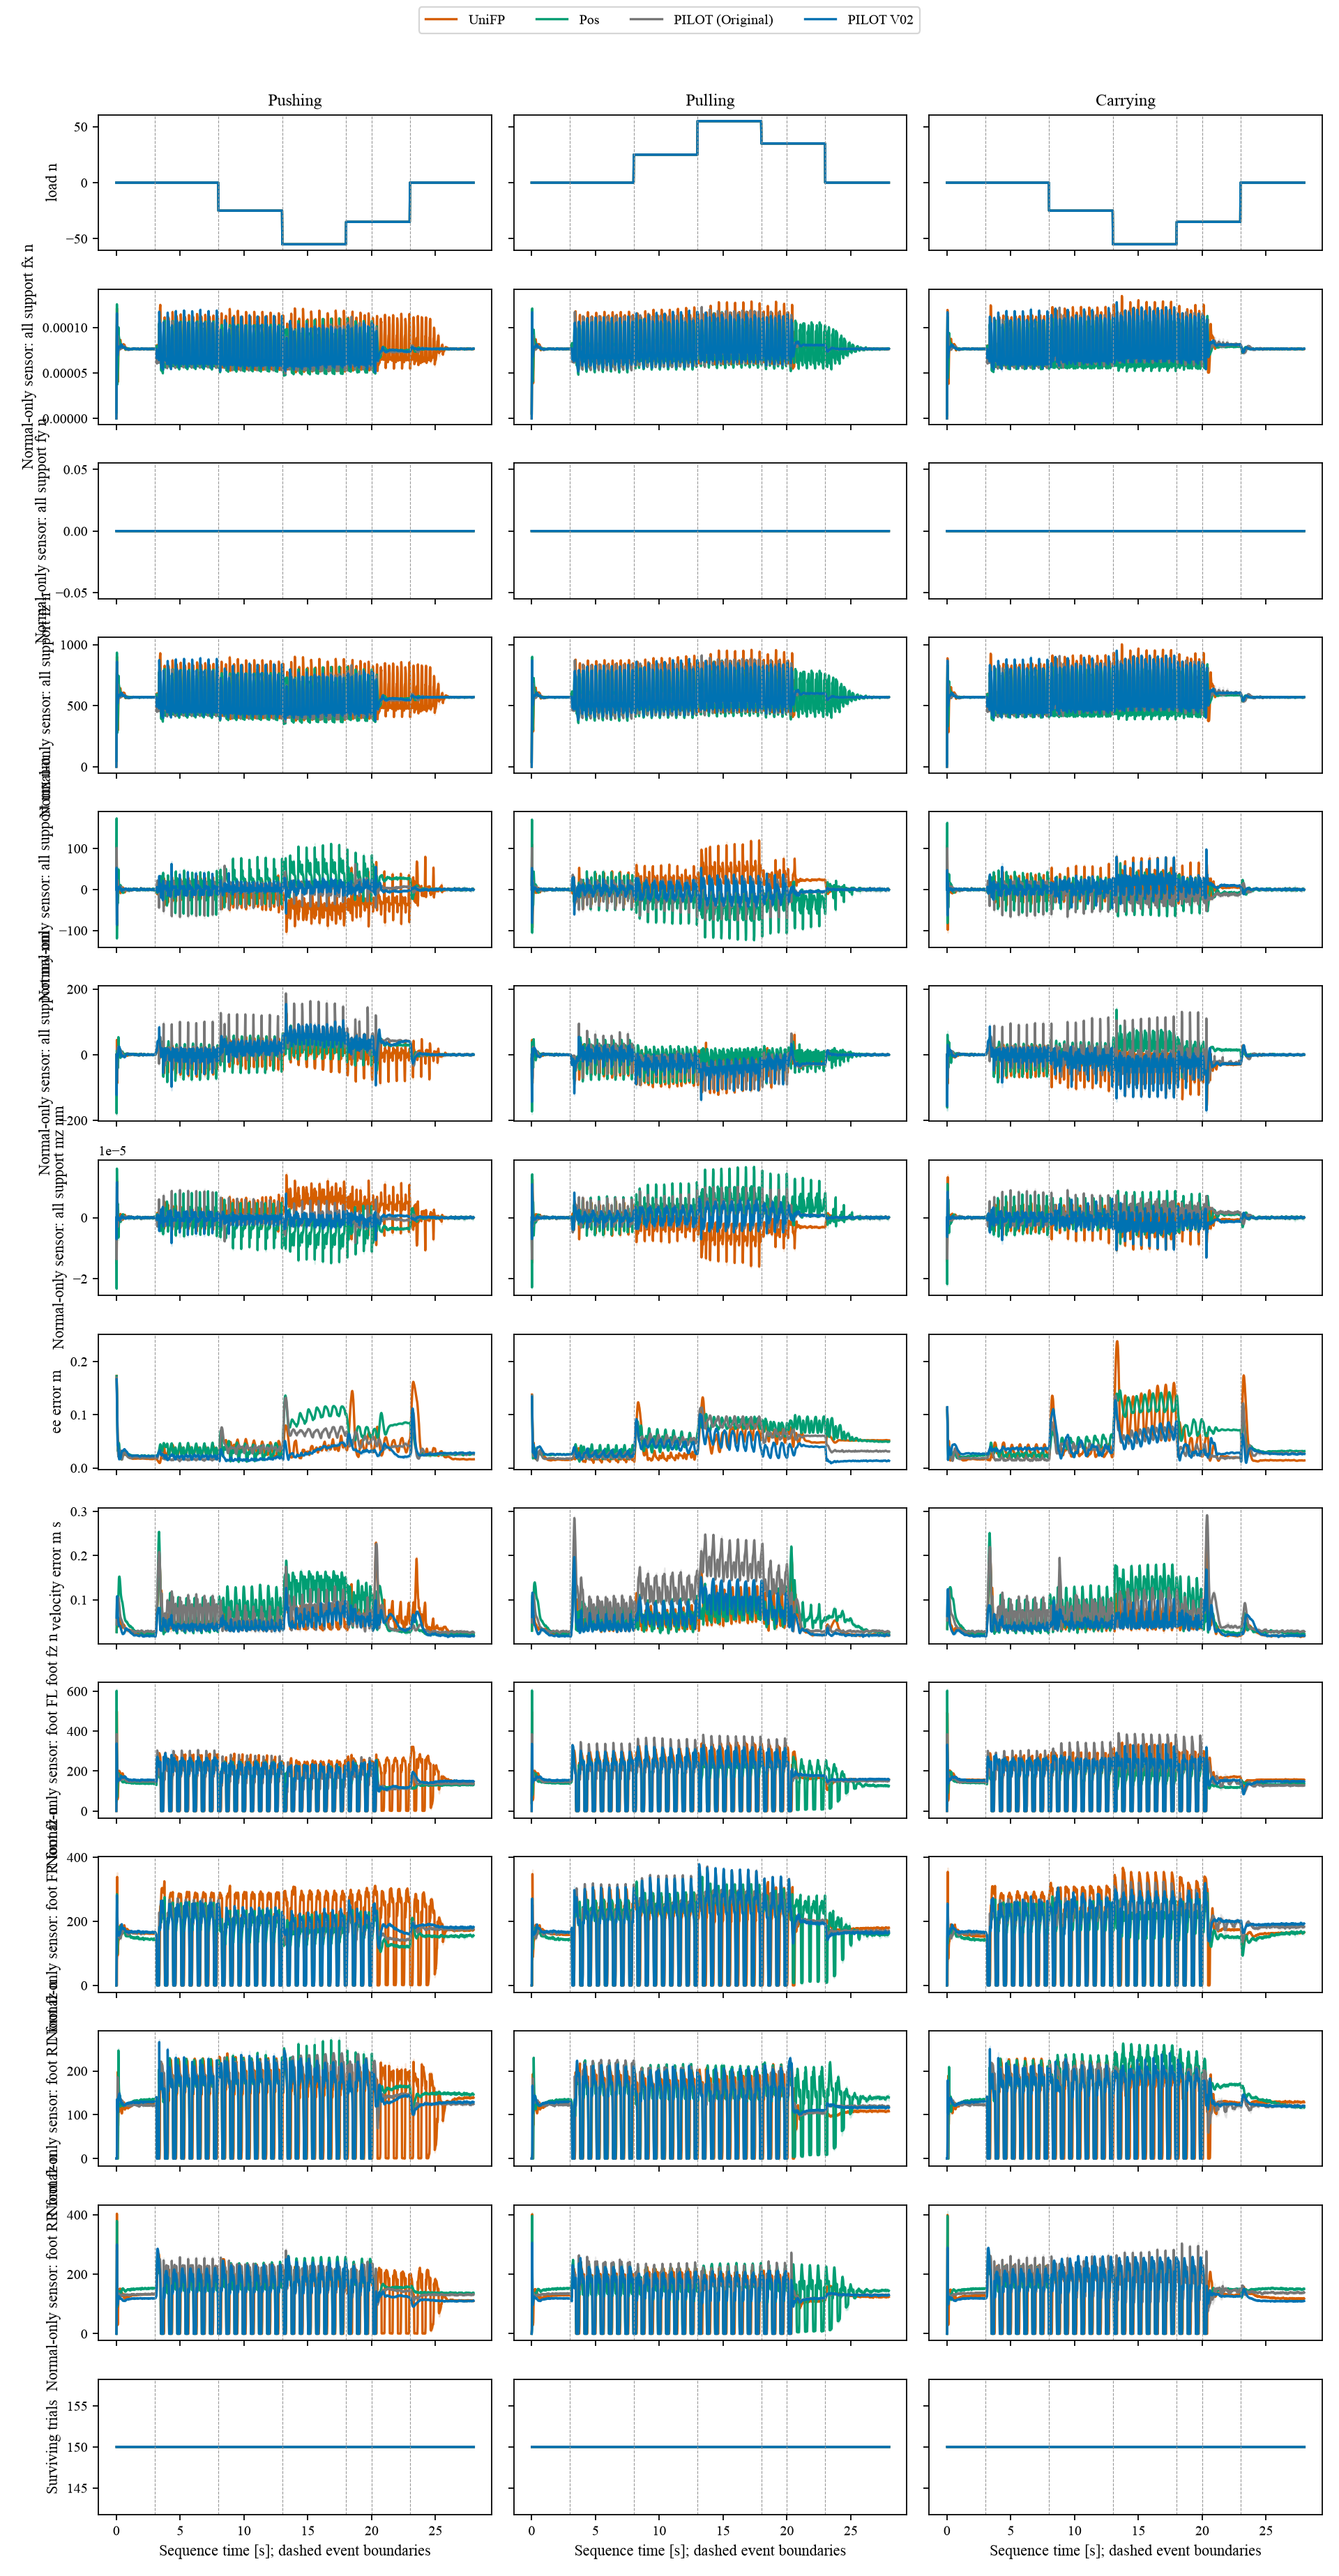

Dedicated CIs: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/pilot_v02_comparison/exp3/action_support/support_metric_confidence_intervals.csv


In [5]:
if CONFIG["run_support"]:
    import exp3_support as support_analysis
    support_analysis = importlib.reload(support_analysis)
    SUPPORT, inventory = cohort.support_config(CONFIG)
    display(pd.DataFrame(inventory))
    support = support_analysis.analyze(SUPPORT)
    display(pd.DataFrame(support["summary"]))
    support_ci = cohort.support_confidence_intervals(support, CONFIG)
    display(support_ci)
    print("\n".join(support["diagnostics"]))
    support_dir = Path(SUPPORT["output_dir"]) / "action_support"
    for path in sorted(support_dir.glob("*.png")):
        display(Image(filename=str(path)))
    print("Dedicated CIs:", support_dir / "support_metric_confidence_intervals.csv")


## Confidence Intervals
Dedicated CSVs report **V02 minus comparator** in native units (tracking fractions remain fractions; physical-limit percentages remain percentages). Broad metric CIs bootstrap paired **evaluation-seed summaries**, preserving the original trial weighting, pooled limit denominators, recovery censoring, and stage definitions. They are pointwise, exploratory fixed-checkpoint intervals, not independent-training uncertainty; three seeds give limited precision. Missing metrics stay unavailable. Distribution plots remain descriptive, not additional significance tests.

Representation `paired_rollout_*` files retain matching audits, trial pairs, and common-time sensitivity. Broad representation CIs also retain per-axis/bias/phase/motion and reference-variant strata. Support CIs are stage-level, not per-timestep significance tests. Cached numerical reductions can be reused; raw recordings are never changed.